<a href="https://colab.research.google.com/github/maivu18082005-hub/Parameter_Identification_of_PMSM_using_PINN_02/blob/main/DBTT_05_trainer_huan_luyen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sổ tay 05: Bộ huấn luyện và huấn luyện MLP

**Dự án:** Nhận dạng tham số động cơ PMSM: mạng MLP nhận dạng Ld, Lq theo (id, iq); Rs tính đại số từ Ld, Lq đã nhận dạng.

**Nguyên tắc:** sổ tay chạy độc lập; mỗi lần chạy đều thiết lập lại môi trường từ đầu. Mã được viết, kiểm thử bằng dữ liệu mẫu, xuất thành tệp `.py` rồi đẩy lên GitHub theo bốn bước của PRD.

### Sơ đồ khối của sổ tay (BPMN 2.0, ISO/IEC 19510)



*Hình: Sơ đồ khối quá trình của sổ tay 05*

## Cell 1 – Thiết lập môi trường

In [1]:
# Cell 1 - Thiết lập môi trường từ đầu: gắn Drive, nhận mã truy cập, sao chép kho mã
import os  # Thao tác đường dẫn và tệp
import sys  # Điều chỉnh đường dẫn nạp mô-đun
import subprocess  # Chạy lệnh git và pip
from google.colab import drive, userdata  # Gắn Drive và đọc bí mật của Colab
drive.mount('/content/drive')  # Gắn Google Drive vào phiên Colab
GITHUB_USER = 'maivu18082005-hub'  # Tài khoản GitHub chứa kho mã
REPO_NAME = 'Parameter_Identification_of_PMSM_using_PINN_02'  # Tên kho mã
REPO_DIR = f'/content/{REPO_NAME}'  # Thư mục kho trên máy Colab
TOKEN = userdata.get('GITHUB_TOKEN')  # Mã truy cập lấy từ Colab Secrets
REMOTE = f'https://{TOKEN}@github.com/{GITHUB_USER}/{REPO_NAME}.git'  # Địa chỉ kho kèm mã truy cập


def run(cmd, check=True):  # Hàm chạy lệnh và che mã truy cập trong đầu ra
    r = subprocess.run(cmd, capture_output=True, text=True)  # Chạy lệnh, thu đầu ra
    out = (r.stdout + r.stderr).replace(TOKEN, '***')  # Thay mã truy cập bằng dấu sao
    if check and r.returncode != 0:  # Nếu lệnh lỗi và yêu cầu kiểm tra
        raise RuntimeError(out)  # Báo lỗi kèm đầu ra đã che
    return out  # Trả về đầu ra


def push_files(paths, message):  # Hàm đẩy tệp lên GitHub
    run(['git', '-C', REPO_DIR, 'config', 'user.name', GITHUB_USER])  # Đặt tên người commit
    run(['git', '-C', REPO_DIR, 'config', 'user.email', f'{GITHUB_USER}@users.noreply.github.com'])  # Đặt email người commit
    run(['git', '-C', REPO_DIR, 'add'] + paths)  # Thêm các tệp vào vùng chờ
    if not run(['git', '-C', REPO_DIR, 'status', '--porcelain']).strip():  # Nếu không có thay đổi
        print('Không có thay đổi để đẩy')  # Thông báo
        return  # Kết thúc hàm
    run(['git', '-C', REPO_DIR, 'commit', '-m', message])  # Tạo commit
    run(['git', '-C', REPO_DIR, 'branch', '-M', 'main'])  # Đảm bảo nhánh là main
    run(['git', '-C', REPO_DIR, 'pull', '--rebase', REMOTE, 'main'], check=False)  # Đồng bộ trước khi đẩy
    print(run(['git', '-C', REPO_DIR, 'push', REMOTE, 'HEAD:main']))  # Đẩy lên GitHub


if os.path.isdir(os.path.join(REPO_DIR, '.git')):  # Nếu kho đã có trên máy
    run(['git', '-C', REPO_DIR, 'pull', REMOTE, 'main'], check=False)  # Cập nhật kho
else:  # Nếu chưa có
    run(['git', 'clone', REMOTE, REPO_DIR])  # Sao chép kho từ GitHub
sys.path.insert(0, REPO_DIR)  # Cho phép nạp mô-đun từ kho
TESTS_OK = False  # Cờ cho phép đẩy mã, chỉ bật sau khi kiểm thử đạt
print('Kho mã sẵn sàng tại', REPO_DIR)  # Thông báo hoàn tất

req = os.path.join(REPO_DIR, 'requirements.txt')  # Tệp yêu cầu thư viện
if os.path.exists(req):  # Nếu tệp tồn tại
    run([sys.executable, '-m', 'pip', 'install', '-q', '-r', req])  # Cài thư viện
import torch  # Thư viện học sâu
from src.utils.common import load_config, set_seed, get_paths  # Tiện ích dùng chung
cfg = load_config(os.path.join(REPO_DIR, 'configs', 'config.yaml'))  # Nạp cấu hình
set_seed(cfg['project']['seed'])  # Cố định hạt giống
PATHS = get_paths(cfg)  # Đường dẫn tuyệt đối trên Drive
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'  # Chọn thiết bị tính toán
print('Thiết bị:', DEVICE, '| Torch:', torch.__version__)  # In thông tin môi trường

Mounted at /content/drive
Kho mã sẵn sàng tại /content/Parameter_Identification_of_PMSM_using_PINN_02
Thiết bị: cpu | Torch: 2.14.1+cpu


## Cell 2 – Nạp dữ liệu, thống kê nhãn và kiểm tra điều kiện đầu vào

In [2]:
# Cell 2 - Kiểm tra điều kiện đầu vào và nạp bộ dữ liệu
import copy  # Sao chép cấu hình
import json  # Đọc ghi JSON
import importlib  # Nạp lại mô-đun
import numpy as np  # Thư viện số học mảng
import pandas as pd  # Thư viện bảng dữ liệu
from src.data.dataset import build_dataloaders  # Hàm dựng bộ nạp dữ liệu
from src.models.ld_lq_mlp import build_mlp, LdLqMLP  # Hàm dựng MLP và lớp mạng
os.makedirs(PATHS['models'], exist_ok=True)  # Đảm bảo thư mục trọng số tồn tại
os.makedirs(PATHS['results'], exist_ok=True)  # Đảm bảo thư mục kết quả tồn tại
assert os.path.exists(os.path.join(PATHS['processed'], 'stats.json')), 'Chạy sổ tay 02 trước để tạo stats.json'  # Dừng nếu thiếu
with open(os.path.join(PATHS['processed'], 'stats.json'), encoding='utf-8') as fh:  # Mở thống kê nhãn
    stats = json.load(fh)  # Đọc thống kê
sets, loaders = build_dataloaders(cfg, PATHS['processed'])  # Dựng tập và bộ nạp
print({k: len(v) for k, v in sets.items()})  # In số mẫu từng tập

{'train': 899940, 'val': 299980, 'test': 299980}


## Cell 3 – Viết `src/training/trainer.py`
Hàm mất mát là sai số bình phương trung bình của Ld, Lq sau khi chia cho giá trị tham chiếu `ld_ref`, `lq_ref` (sai số tương đối nên Ld và Lq có trọng số ngang nhau dù chênh độ lớn). Bộ huấn luyện dùng Adam, cắt gradient, giảm tốc độ học theo kiểm định, dừng sớm và lưu điểm tốt nhất.

In [3]:
%%writefile /content/Parameter_Identification_of_PMSM_using_PINN_02/src/training/trainer.py
"""Hàm mất mát và bộ huấn luyện MLP nhận dạng Ld, Lq: Adam, cắt gradient, dừng sớm, lưu điểm tốt nhất."""  # Mô tả mô-đun
import json  # Ghi nhật ký JSON
import os  # Thao tác đường dẫn
import time  # Đo thời gian huấn luyện
import torch  # Thư viện học sâu
import torch.nn as nn  # Các lớp mạng nơ-ron


class RelativeMSE(nn.Module):  # Hàm mất mát
    """Sai số bình phương trung bình của (Ld, Lq) sau khi chia cho giá trị tham chiếu."""  # Mô tả lớp

    def __init__(self, ref):  # Hàm khởi tạo
        """Nhận giá trị tham chiếu (Ld, Lq) để chuẩn hóa sai số."""  # Mô tả hàm
        super().__init__()  # Gọi lớp cha
        self.register_buffer("ref", torch.tensor(ref, dtype=torch.float32))  # Lưu giá trị tham chiếu

    def forward(self, pred, target):  # Tính mất mát
        """Trả về MSE của sai số tương đối so với tham chiếu."""  # Mô tả hàm
        return (((pred - target) / self.ref) ** 2).mean()  # Bình phương, lấy trung bình


def build_loss(cfg):  # Hàm dựng mất mát từ cấu hình
    """Dựng RelativeMSE với tham chiếu (ld_ref, lq_ref) của cấu hình."""  # Mô tả hàm
    m = cfg["motor"]  # Nhóm thông số động cơ
    return RelativeMSE([m["ld_ref"], m["lq_ref"]])  # Dựng mất mát


class Trainer:  # Lớp bộ huấn luyện
    """Huấn luyện mô hình với Adam, cắt gradient, giảm tốc độ học và dừng sớm."""  # Mô tả lớp

    def __init__(self, model, loss_fn, loaders, cfg, device, save_dir, name):  # Hàm khởi tạo
        """Nhận mô hình, mất mát, bộ nạp dữ liệu, cấu hình và nơi lưu."""  # Mô tả hàm
        t = cfg["train"]  # Nhóm cấu hình huấn luyện
        self.model, self.loss_fn, self.loaders = model.to(device), loss_fn.to(device), loaders  # Lưu đối tượng chính
        self.cfg, self.device, self.name = cfg, device, name  # Lưu cấu hình, thiết bị, tên
        self.opt = torch.optim.Adam(self.model.parameters(), lr=t["lr"], weight_decay=t["weight_decay"])  # Bộ tối ưu Adam
        self.sched = torch.optim.lr_scheduler.ReduceLROnPlateau(self.opt, factor=0.5, patience=max(1, t["patience"] // 3))  # Giảm tốc độ học khi chững
        self.ckpt = os.path.join(save_dir, f"{name}_best.pt")  # Đường dẫn điểm tốt nhất
        self.history = []  # Nhật ký các kỷ nguyên

    def _run_epoch(self, split):  # Chạy một kỷ nguyên
        """Chạy một kỷ nguyên trên tập split và trả về mất mát trung bình."""  # Mô tả hàm
        train = split == "train"  # Cờ chế độ huấn luyện
        self.model.train(train)  # Bật hoặc tắt chế độ huấn luyện
        tot, n = 0.0, 0  # Bộ tích lũy
        for batch in self.loaders[split]:  # Duyệt từng lô
            x, y = batch["x"].to(self.device), batch["y"].to(self.device)  # Chuyển lô sang thiết bị
            with torch.set_grad_enabled(train):  # Chỉ tính gradient khi huấn luyện
                loss = self.loss_fn(self.model(x), y)  # Lan truyền thuận và tính mất mát
            if train:  # Nếu đang huấn luyện
                self.opt.zero_grad()  # Xóa gradient cũ
                loss.backward()  # Lan truyền ngược
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg["train"]["grad_clip"])  # Cắt gradient
                self.opt.step()  # Cập nhật trọng số
            k = x.shape[0]  # Kích thước lô
            tot, n = tot + float(loss.detach()) * k, n + k  # Cộng dồn mất mát
        return tot / n  # Trả về trung bình

    def fit(self):  # Vòng huấn luyện chính
        """Huấn luyện tới khi hết kỷ nguyên hoặc dừng sớm; trả về nhật ký."""  # Mô tả hàm
        t, best, wait, t0 = self.cfg["train"], float("inf"), 0, time.time()  # Trạng thái ban đầu
        for ep in range(t["epochs"]):  # Duyệt từng kỷ nguyên
            tr = self._run_epoch("train")  # Huấn luyện
            va = self._run_epoch("val")  # Kiểm định
            self.sched.step(va)  # Cập nhật tốc độ học
            self.history.append({"epoch": ep, "train": tr, "val": va, "lr": self.opt.param_groups[0]["lr"]})  # Ghi nhật ký
            if va < best:  # Nếu cải thiện
                best, wait = va, 0  # Đặt lại bộ đếm
                self.save()  # Lưu điểm tốt nhất
            else:  # Nếu không cải thiện
                wait += 1  # Tăng bộ đếm chờ
            if wait >= t["patience"]:  # Hết kiên nhẫn
                break  # Dừng sớm
        if not os.path.exists(self.ckpt):  # Nếu chưa có điểm lưu nào
            self.save()  # Lưu trạng thái cuối
        return {"history": self.history, "best_val": best, "seconds": time.time() - t0}  # Trả về kết quả

    def save(self):  # Lưu điểm kiểm tra
        """Lưu trọng số và cấu hình kiến trúc."""  # Mô tả hàm
        torch.save({"state_dict": self.model.state_dict(), "arch": self.model.get_config()}, self.ckpt)  # Ghi tệp .pt

    def save_history(self, path):  # Lưu nhật ký
        """Ghi nhật ký huấn luyện ra tệp JSON."""  # Mô tả hàm
        with open(path, "w", encoding="utf-8") as f:  # Mở tệp ghi
            json.dump(self.history, f, ensure_ascii=False, indent=1)  # Ghi JSON

Writing /content/Parameter_Identification_of_PMSM_using_PINN_02/src/training/trainer.py


## Cell 4 – Kiểm thử đơn vị trên dữ liệu tổng hợp nhỏ
Kiểm tra mất mát bằng 0 và bằng giá trị đã biết, mất mát huấn luyện giảm, tệp điểm lưu được tạo và nạp lại được, dừng sớm hoạt động và hai lần chạy cùng hạt giống cho cùng kết quả. Dữ liệu tổng hợp có Ld, Lq phụ thuộc trơn vào (id, iq); không dùng dữ liệu thật nên kiểm thử không phụ thuộc Drive.

In [4]:
# Cell 4 - Kiểm thử đơn vị cho trainer.py bằng dữ liệu tổng hợp nhỏ
import tempfile  # Thư mục tạm
from torch.utils.data import Dataset, DataLoader  # Lớp tập dữ liệu và bộ nạp
import src.training.trainer as tr  # Mô-đun cần kiểm thử
importlib.reload(tr)  # Dùng bản mới ghi
ref_t = [cfg['motor']['ld_ref'], cfg['motor']['lq_ref']]  # Giá trị tham chiếu
lf = tr.RelativeMSE(ref_t)  # Hàm mất mát
tgt = torch.tensor([[1.2e-3, 1.4e-3]])  # Nhãn thử
assert float(lf(tgt, tgt)) == 0.0, 'Mất mát phải bằng 0 khi dự đoán đúng'  # Kiểm tra bằng 0
assert abs(float(lf(tgt + torch.tensor([ref_t]) * 0.1, tgt)) - 0.01) < 1e-6, 'Lệch 10% giá trị tham chiếu phải cho mất mát 0,01'  # Kiểm tra giá trị đã biết
assert torch.equal(tr.build_loss(cfg).ref, torch.tensor(ref_t, dtype=torch.float32)), 'build_loss phải lấy ld_ref, lq_ref từ cấu hình'  # Kiểm tra cấu hình


class Synth(Dataset):  # Tập dữ liệu tổng hợp: Ld, Lq giảm trơn theo độ lớn dòng
    def __init__(self, n, seed):  # Hàm khởi tạo
        g = torch.Generator().manual_seed(seed)  # Bộ sinh ngẫu nhiên
        i_d, i_q = -40 * torch.rand(n, generator=g), 60 * torch.rand(n, generator=g)  # Dòng ngẫu nhiên
        ld = 1.3e-3 - 5e-6 * (-i_d) - 2e-6 * i_q  # Ld phụ thuộc id, iq
        lq = 1.5e-3 - 5e-6 * i_q + 2e-6 * i_d  # Lq phụ thuộc id, iq
        self.x, self.y = torch.stack([i_d, i_q], 1), torch.stack([ld, lq], 1)  # Đầu vào và nhãn

    def __len__(self):  # Số mẫu
        return len(self.x)  # Trả về số mẫu

    def __getitem__(self, i):  # Lấy một mẫu
        return {'x': self.x[i], 'y': self.y[i]}  # Gói mẫu


def make_loaders():  # Dựng bộ nạp tổng hợp cố định hạt giống
    return {'train': DataLoader(Synth(1024, 1), batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(0)), 'val': DataLoader(Synth(256, 2), batch_size=128)}  # Hai bộ nạp


def make_model(c):  # Dựng MLP với cận đầu ra của dữ liệu tổng hợp
    return LdLqMLP([cfg['motor']['i_rated_peak']] * 2, [0.9e-3, 1.1e-3], [1.4e-3, 1.6e-3], c['model']['hidden_sizes'], c['model']['activation'])  # Dựng mạng


tcfg = copy.deepcopy(cfg)  # Sao chép cấu hình để thử
tcfg['train'].update({'epochs': 40, 'patience': 10, 'batch_size': 128, 'lr': 3e-3})  # Cấu hình huấn luyện ngắn
tmp = tempfile.mkdtemp()  # Thư mục tạm
set_seed(1)  # Cố định hạt giống lần một
t1 = tr.Trainer(make_model(tcfg), tr.build_loss(tcfg), make_loaders(), tcfg, 'cpu', tmp, 'unit')  # Bộ huấn luyện lần một
r1 = t1.fit()  # Huấn luyện
assert r1['history'][-1]['train'] < 0.5 * r1['history'][0]['train'], 'Mất mát huấn luyện phải giảm ít nhất một nửa'  # Kiểm tra giảm
assert os.path.exists(os.path.join(tmp, 'unit_best.pt')), 'Phải có tệp điểm lưu tốt nhất'  # Kiểm tra tệp lưu
ck = torch.load(os.path.join(tmp, 'unit_best.pt'), map_location='cpu')  # Đọc điểm lưu
re = LdLqMLP(**ck['arch'])  # Dựng lại mạng từ kiến trúc đã lưu
re.load_state_dict(ck['state_dict'])  # Nạp trọng số
assert re.get_config() == t1.model.get_config(), 'Điểm lưu phải đủ để dựng lại mạng'  # Kiểm tra kiến trúc
set_seed(1)  # Đặt lại hạt giống
r2 = tr.Trainer(make_model(tcfg), tr.build_loss(tcfg), make_loaders(), tcfg, 'cpu', tmp, 'unit2').fit()  # Huấn luyện lần hai
assert abs(r1['history'][-1]['train'] - r2['history'][-1]['train']) < 1e-9, 'Cùng hạt giống phải cho cùng kết quả'  # Kiểm tra tái lập
scfg = copy.deepcopy(tcfg)  # Cấu hình thử dừng sớm
scfg['train'].update({'epochs': 50, 'patience': 1, 'lr': 0.0})  # Tốc độ học bằng 0 nên kiểm định không cải thiện
r3 = tr.Trainer(make_model(scfg), tr.build_loss(scfg), make_loaders(), scfg, 'cpu', tmp, 'early').fit()  # Huấn luyện thử dừng sớm
assert len(r3['history']) < 10, 'Dừng sớm phải kích hoạt'  # Kiểm tra dừng sớm
TESTS_OK = True  # Bật cờ cho phép đẩy mã
print('Toàn bộ kiểm thử đơn vị đạt')  # Thông báo

Toàn bộ kiểm thử đơn vị đạt


## Cell 5 – Huấn luyện MLP trên dữ liệu thật
Huấn luyện trên Data1–3, kiểm định trên Data4. Sau khi huấn luyện, nạp lại điểm tốt nhất và in sai số tương đối của Ld, Lq trên Data4; việc đánh giá chính thức trên Data5 nằm ở sổ tay 06.

In [5]:
# Cell 5 - Huấn luyện MLP trên dữ liệu thật
import time  # Đo thời gian
set_seed(cfg['project']['seed'])  # Cố định hạt giống
model = build_mlp(cfg, stats)  # Dựng mô hình
trainer = tr.Trainer(model, tr.build_loss(cfg), loaders, cfg, DEVICE, PATHS['models'], 'mlp')  # Dựng bộ huấn luyện
out = trainer.fit()  # Huấn luyện
trainer.save_history(os.path.join(PATHS['results'], 'history_mlp.json'))  # Lưu nhật ký
print('mlp | tham số:', model.count_parameters(), '| số kỷ nguyên:', len(out['history']), '| mất mát kiểm định tốt nhất:', out['best_val'], '| thời gian (s):', round(out['seconds'], 1))  # In tóm tắt
ck = torch.load(trainer.ckpt, map_location=DEVICE)  # Nạp điểm tốt nhất
model.load_state_dict(ck['state_dict'])  # Nạp trọng số
model.eval()  # Chuyển sang chế độ suy luận
with torch.no_grad():  # Tắt gradient
    pv = model(sets['val'].x.to(DEVICE)).cpu().numpy().astype(np.float64)  # Dự đoán trên Data4
yv = sets['val'].y.numpy().astype(np.float64)  # Nhãn Data4
ev = np.abs(pv - yv) / np.abs(yv) * 100.0  # Sai số tương đối (%)
print('Sai số tương đối (%) trên Data4, cột (Ld, Lq): trung bình', ev.mean(0).round(3), '| P95', np.percentile(ev, 95, axis=0).round(3), '| cực đại', ev.max(0).round(3))  # In sai số

mlp | tham số: 1218 | số kỷ nguyên: 50 | mất mát kiểm định tốt nhất: 6.727406078508652e-05 | thời gian (s): 567.8
Sai số tương đối (%) trên Data4, cột (Ld, Lq): trung bình [0.342 0.836] | P95 [0.941 3.14 ] | cực đại [2.813 3.648]


## Cell 6 – Vẽ đường cong mất mát
Mất mát huấn luyện và kiểm định theo kỷ nguyên.

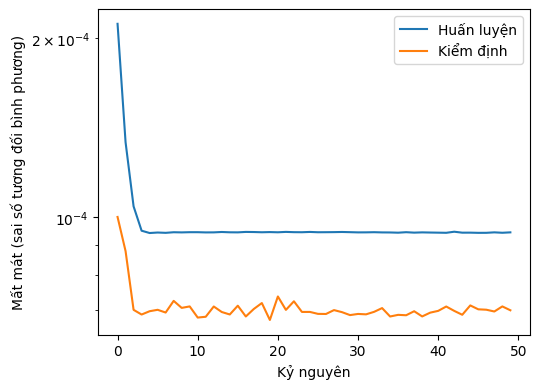

In [6]:
# Cell 6 - Vẽ đường cong mất mát
import matplotlib.pyplot as plt  # Thư viện vẽ đồ thị
h = pd.DataFrame(out['history'])  # Nhật ký thành bảng
fig, ax = plt.subplots(figsize=(5.5, 4))  # Một đồ thị
ax.semilogy(h['epoch'], h['train'], label='Huấn luyện')  # Mất mát huấn luyện
ax.semilogy(h['epoch'], h['val'], label='Kiểm định')  # Mất mát kiểm định
ax.set_xlabel('Kỷ nguyên')  # Nhãn trục hoành
ax.set_ylabel('Mất mát (sai số tương đối bình phương)')  # Nhãn trục tung
ax.legend()  # Chú giải
fig.tight_layout()  # Căn chỉnh bố cục
fig.savefig(os.path.join(PATHS['results'], 'loss_curves.png'), dpi=150)  # Lưu ảnh vào Drive
plt.show()  # Hiển thị ảnh

## Cell 7 – Khảo sát kiến trúc (tùy chọn)
Quét độ rộng và độ sâu lớp ẩn với số kỷ nguyên rút gọn. Đặt `RUN_SWEEP = True` để chạy; kết quả lưu vào `sweep.csv`. Số kỷ nguyên khảo sát `[TBD]`. Chọn kiến trúc theo mất mát kiểm định (Data4), không dùng Data5.

In [7]:
# Cell 7 - Khảo sát kiến trúc (tùy chọn)
RUN_SWEEP = False  # [TBD] Đặt True để chạy khảo sát kiến trúc
SWEEP_EPOCHS = 60  # [TBD] Số kỷ nguyên rút gọn khi khảo sát
rows = []  # Danh sách kết quả khảo sát
if RUN_SWEEP:  # Nếu bật khảo sát
    for hs in ([16, 16], [32, 32], [64, 64], [32, 32, 32]):  # Duyệt các kiến trúc ứng viên
        sc = copy.deepcopy(cfg)  # Sao chép cấu hình
        sc['model']['hidden_sizes'], sc['train']['epochs'] = hs, SWEEP_EPOCHS  # Đặt kiến trúc và số kỷ nguyên
        set_seed(sc['project']['seed'])  # Cố định hạt giống
        mdl = build_mlp(sc, stats)  # Dựng MLP ứng viên
        res = tr.Trainer(mdl, tr.build_loss(sc), loaders, sc, DEVICE, tempfile.mkdtemp(), 'sweep').fit()  # Huấn luyện
        rows.append({'hidden': str(hs), 'params': mdl.count_parameters(), 'best_val': res['best_val']})  # Ghi kết quả
    sweep = pd.DataFrame(rows)  # Bảng kết quả
    sweep.to_csv(os.path.join(PATHS['results'], 'sweep.csv'), index=False)  # Lưu vào Drive
    display(sweep)  # Hiển thị bảng
else:  # Nếu không bật
    print('Bỏ qua khảo sát kiến trúc')  # Thông báo

Bỏ qua khảo sát kiến trúc


## Cell 8 – Bước 4: đẩy lên GitHub
Chỉ mã nguồn được đẩy; trọng số và nhật ký nằm trên Drive.

In [8]:
# Cell cuối - Bước 4: đẩy tệp đã kiểm thử đạt lên GitHub
assert TESTS_OK, 'Chưa đạt toàn bộ kiểm thử, không được đẩy mã'  # Chặn đẩy mã khi kiểm thử chưa đạt
push_files(['src/training/trainer.py'], 'Thêm trainer.py')  # Đẩy các tệp lên nhánh main

To https://github.com/maivu18082005-hub/Parameter_Identification_of_PMSM_using_PINN_02.git
   38ed3d7..5fdaa13  HEAD -> main

